# 04 · Churn Prediction — will an active customer stop buying?

**Business question:** Which currently active customers are likely to **not buy again in the next 90 days**, so the store can try to keep them first?

**Data:** cleaned transactions (see notebook 01).

**Approach:**
1. Pick a **cut-off date** (10 Sep 2011). Build each customer's features **only from purchases before it** — the model must not see the future (no leakage).
2. **Label:** churn = 1 if the customer makes **no purchase in the 90 days after** the cut-off.
3. Keep only **active** customers (bought in the 180 days before the cut-off) — long-gone customers are trivially "churned" and would make the problem fake-easy.
4. Compare **Logistic Regression, KNN, SVM, Decision Tree and Random Forest** with **10-fold cross-validation**, tune the best with **GridSearchCV**, test once.

## Importing the libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# folder for saving plots (repo: ../images, Kaggle: current folder)
IMG_DIR = '../images' if os.path.isdir('../images') else '.'

## Importing the dataset

In [2]:
# Automatically finds both CSV files under /kaggle/input (Kaggle) or ../data (local) - no manual path copying needed
files_needed = ['online_retail_09_10.csv', 'online_retail_10_11.csv']
paths = {}
for root in ['/kaggle/input', '../data', 'data']:
    for dirname, _, filenames in os.walk(root):
        for filename in filenames:
            if filename in files_needed and filename not in paths:
                paths[filename] = os.path.join(dirname, filename)

if len(paths) < 2:
    print("CSV files not found - attach the 'UCI Online Retail II' dataset under Input (Kaggle) or put them in ../data")
else:
    for f in files_needed:
        print("Found it at:", paths[f])
    # the files start with a hidden BOM character, so 'utf-8-sig' keeps the first column name clean
    dataset = pd.concat([pd.read_csv(paths[f], encoding='utf-8-sig') for f in files_needed], ignore_index=True)
    print(dataset.shape)

Found it at: ../data/online_retail_09_10.csv
Found it at: ../data/online_retail_10_11.csv


(1067371, 8)


## Cleaning the data

In [3]:
# Same cleaning as notebook 01 (explained step by step there)
dataset = dataset.drop_duplicates()                                    # also removes the overlap between the 2 files
dataset['InvoiceNo'] = dataset['InvoiceNo'].astype(str)
dataset['StockCode'] = dataset['StockCode'].astype(str)
dataset['InvoiceDate'] = pd.to_datetime(dataset['InvoiceDate'], format='%m/%d/%Y %H:%M')
dataset = dataset[~dataset['InvoiceNo'].str.startswith('C')]           # cancelled orders
dataset = dataset[(dataset['Quantity'] > 0) & (dataset['UnitPrice'] > 0)]
dataset = dataset.dropna(subset=['CustomerID'])                        # we need to know the customer
dataset = dataset[dataset['StockCode'].str.match(r'^\d')]             # keep real products (drop POST, M, BANK CHARGES...)
dataset['CustomerID'] = dataset['CustomerID'].astype(int)
dataset['Description'] = dataset['Description'].str.strip()           # remove stray spaces in product names
dataset['Revenue'] = dataset['Quantity'] * dataset['UnitPrice']
print(dataset.shape)

(776577, 9)


## Building the churn dataset

In [4]:
cutoff = pd.Timestamp('2011-09-10')
past = dataset[dataset['InvoiceDate'] < cutoff]                                   # what we are allowed to see
future = dataset[(dataset['InvoiceDate'] >= cutoff) &
                 (dataset['InvoiceDate'] < cutoff + pd.Timedelta(days=90))]       # only used for the label

customers = past.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (cutoff - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum'),
    Tenure=('InvoiceDate', lambda x: (cutoff - x.min()).days),
    Products=('StockCode', 'nunique')).reset_index()
customers['AvgOrderValue'] = customers['Monetary'] / customers['Frequency']

customers['Churn'] = (~customers['CustomerID'].isin(future['CustomerID'].unique())).astype(int)

# keep active customers only
customers = customers[customers['Recency'] <= 180].reset_index(drop=True)
print(customers.shape)
print("Churn rate: {:.1f} %".format(customers['Churn'].mean() * 100))
customers.head()

(2785, 8)
Churn rate: 38.2 %


,CustomerID,Recency,Frequency,Monetary,Tenure,Products,AvgOrderValue,Churn
0,12347,38,6,3402.39,313,107,567.065000,0
1,12348,157,4,1388.40,347,24,347.100000,0
2,12352,171,6,985.31,301,36,164.218333,0
3,12353,113,2,406.76,317,23,203.380000,1
4,12354,141,1,1079.40,141,58,1079.400000,1


In [5]:
dataset_churn = customers[['CustomerID', 'Recency', 'Frequency', 'Monetary', 'Tenure', 'Products', 'AvgOrderValue', 'Churn']]
X = dataset_churn.iloc[:, 1:-1].values
y = dataset_churn.iloc[:, -1].values
feature_names = list(dataset_churn.columns[1:-1])
print(feature_names)

['Recency', 'Frequency', 'Monetary', 'Tenure', 'Products', 'AvgOrderValue']


All features are heavily skewed (a few huge wholesalers), so we use `log(1 + x)` before scaling.

In [6]:
X = np.log1p(X)

## Splitting the dataset into the Training set and Test set
`stratify=y` keeps the same churn rate in both sets.

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
print(X_train.shape, X_test.shape)

(2088, 6) (697, 6)


## Comparing models with k-Fold Cross Validation
The scaler goes **inside a pipeline**, so in every fold it is fitted only on that fold's training part — no leakage into the validation fold. The test set is not touched here.

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

classifiers = {
    'Logistic Regression': LogisticRegression(random_state=0),
    'KNN': KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2),
    'Kernel SVM': SVC(kernel='rbf', random_state=0),
    'Decision Tree': DecisionTreeClassifier(criterion='entropy', random_state=0),
    'Random Forest': RandomForestClassifier(n_estimators=100, criterion='entropy', random_state=0)}

rows = []
for name, classifier in classifiers.items():
    scores = cross_validate(estimator=make_pipeline(StandardScaler(), classifier), X=X_train, y=y_train, cv=10,
                            scoring=['accuracy', 'recall', 'f1', 'roc_auc'])
    rows.append([name] + [f"{scores['test_' + m].mean()*100:.2f} ± {scores['test_' + m].std()*100:.2f}"
                          for m in ['accuracy', 'recall', 'f1', 'roc_auc']])
    print(name, "done")

cv_results = pd.DataFrame(rows, columns=['Model', 'Accuracy %', 'Recall %', 'F1 %', 'ROC-AUC %'])
cv_results

Logistic Regression done


KNN done


Kernel SVM done


Decision Tree done


Random Forest done


,Model,Accuracy %,Recall %,F1 %,ROC-AUC %
0,Logistic Regression,70.21 ± 3.30,52.52 ± 4.79,57.39 ± 4.30,76.07 ± 3.84
1,KNN,67.24 ± 2.41,52.64 ± 3.54,55.12 ± 3.03,69.98 ± 3.88
2,Kernel SVM,70.17 ± 2.73,47.50 ± 3.35,54.91 ± 3.62,74.47 ± 3.97
3,Decision Tree,62.50 ± 2.87,51.52 ± 5.46,51.15 ± 3.92,60.41 ± 2.96
4,Random Forest,69.16 ± 3.13,51.89 ± 4.45,56.25 ± 4.22,73.53 ± 4.02


**Reading the table:** the simplest model, **Logistic Regression**, is as good as or better than the complex ones on ROC-AUC — the churn signal here is mostly *recency and frequency*, which a linear model captures well. The **Decision Tree** is clearly worst (high variance: it overfits). Recall is only ~50% at the default 0.5 threshold, so next we tune for F1 and let the model weight churners more.

## Applying Grid Search to find the best model and the best parameters

In [9]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
pipe = Pipeline([('sc', StandardScaler()), ('classifier', LogisticRegression(random_state=0))])
parameters = [{'classifier': [LogisticRegression(random_state=0, max_iter=1000)],
               'classifier__C': [0.01, 0.1, 1, 10],
               'classifier__class_weight': [None, 'balanced']},
              {'classifier': [RandomForestClassifier(random_state=0)],
               'classifier__n_estimators': [100, 300],
               'classifier__max_depth': [3, 5, 8],
               'classifier__class_weight': [None, 'balanced']}]
grid_search = GridSearchCV(estimator=pipe, param_grid=parameters, scoring='f1', cv=10, n_jobs=-1)
grid_search.fit(X_train, y_train)
best_accuracy = grid_search.best_score_
best_parameters = grid_search.best_params_
print("Best F1: {:.2f} %".format(best_accuracy * 100))
print("Best Parameters:", best_parameters)

Best F1: 63.34 %
Best Parameters: {'classifier': RandomForestClassifier(random_state=0), 'classifier__class_weight': 'balanced', 'classifier__max_depth': 5, 'classifier__n_estimators': 100}


## Final model: evaluating once on the Test set

In [10]:
classifier = grid_search.best_estimator_      # already retrained on the full training set
y_pred = classifier.predict(X_test)
y_prob = classifier.predict_proba(X_test)[:, 1]

## Making the Confusion Matrix

In [11]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, roc_auc_score, f1_score, recall_score, precision_score
cm = confusion_matrix(y_test, y_pred)
print(cm)
print("Accuracy : {:.2f} %".format(accuracy_score(y_test, y_pred) * 100))
print("Precision: {:.2f} %".format(precision_score(y_test, y_pred) * 100))
print("Recall   : {:.2f} %".format(recall_score(y_test, y_pred) * 100))
print("F1       : {:.2f} %".format(f1_score(y_test, y_pred) * 100))
print("ROC-AUC  : {:.2f} %".format(roc_auc_score(y_test, y_prob) * 100))

[[269 161]
 [ 61 206]]
Accuracy : 68.15 %
Precision: 56.13 %
Recall   : 77.15 %
F1       : 64.98 %
ROC-AUC  : 76.17 %


In [12]:
print(classification_report(y_test, y_pred, target_names=['Stays', 'Churns']))

              precision    recall  f1-score   support

       Stays       0.82      0.63      0.71       430
      Churns       0.56      0.77      0.65       267

    accuracy                           0.68       697
   macro avg       0.69      0.70      0.68       697
weighted avg       0.72      0.68      0.69       697



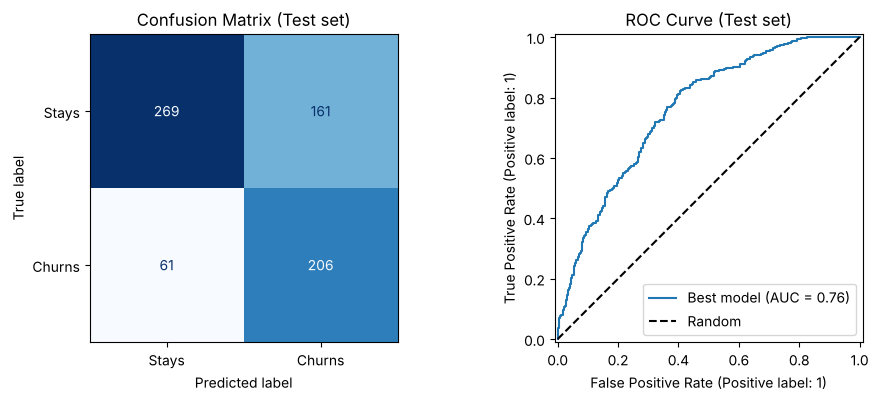

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(cm, display_labels=['Stays', 'Churns']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion Matrix (Test set)')
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1], name='Best model')
axes[1].plot([0, 1], [0, 1], 'k--', label='Random')
axes[1].set_title('ROC Curve (Test set)')
axes[1].legend()
plt.savefig(f'{IMG_DIR}/04_confusion_roc.png', dpi=120, bbox_inches='tight')
plt.show()

## What drives churn?

AvgOrderValue    0.075
Tenure           0.101
Recency          0.133
Products         0.172
Monetary         0.230
Frequency        0.291
dtype: float64


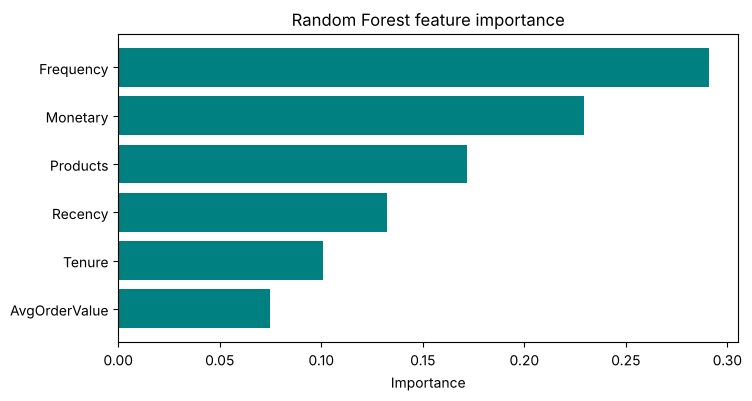

In [14]:
model = classifier.named_steps['classifier']
if hasattr(model, 'coef_'):
    importance = pd.Series(model.coef_[0], index=feature_names).sort_values()
    title, xlabel = 'Logistic Regression coefficients (scaled log features)', '← lowers churn risk | raises churn risk →'
else:
    importance = pd.Series(model.feature_importances_, index=feature_names).sort_values()
    title, xlabel = 'Random Forest feature importance', 'Importance'
print(importance.round(3))

plt.figure(figsize=(8, 4))
bar_colors = ['green' if v < 0 else 'red' for v in importance.values] if hasattr(model, 'coef_') else 'teal'
plt.barh(importance.index, importance.values, color=bar_colors)
plt.title(title)
plt.xlabel(xlabel)
plt.savefig(f'{IMG_DIR}/04_churn_drivers.png', dpi=120, bbox_inches='tight')
plt.show()

## Business impact

In [15]:
test_customers = dataset_churn.iloc[train_test_split(np.arange(len(dataset_churn)), test_size=0.25, random_state=0, stratify=y)[1]]
test_customers = test_customers.assign(Predicted=y_pred, Probability=y_prob)

flagged = test_customers[test_customers['Predicted'] == 1]
caught = flagged[flagged['Churn'] == 1]
actual_churners = test_customers[test_customers['Churn'] == 1]

print("Test customers                        :", len(test_customers))
print("Flagged as at risk                    :", len(flagged))
print("Real churners caught                  : {} of {} ({:.1f} %)".format(len(caught), len(actual_churners), len(caught) / len(actual_churners) * 100))
print("Past revenue of churners caught       : £{:,.0f} ({:.1f} % of all churners' past revenue)".format(
    caught['Monetary'].sum(), caught['Monetary'].sum() / actual_churners['Monetary'].sum() * 100))

Test customers                        : 697
Flagged as at risk                    : 367
Real churners caught                  : 206 of 267 (77.2 %)
Past revenue of churners caught       : £156,970 (44.7 % of all churners' past revenue)


## Results and recommendations

- **Default settings:** Logistic Regression had the best ROC-AUC and F1 under 10-fold CV, and the Decision Tree was clearly worst (it overfits).
- **After tuning for F1:** Grid Search chose a **Random Forest with `max_depth=5` and `class_weight='balanced'`**. Limiting depth controls variance; balanced weights make missing a churner cost more. Recall jumped from ~52% (default models) to **77% on the test set**, at the price of more false alarms (precision 56%). For a cheap retention email, catching more churners is worth a few unnecessary emails.
- **Drivers:** how often a customer buys (Frequency) and how much they have spent (Monetary) matter most, followed by product variety and Recency.
- **Business view:** the churners the model catches hold only **~45% of all churners' past revenue** — it is better at spotting small, infrequent buyers than big accounts that suddenly stop. Big accounts need a separate rule (e.g. alert when a top customer's usual order gap is exceeded).
- **Action:** each week, score active customers, send win-back offers to the flagged ones starting with the highest past spend, and have account managers watch the top customers directly.

**Limitations:** one cut-off date only (a production version would use several, i.e. time-based validation); behaviour features only (no marketing, website or product-return data); "churn" is defined as no purchase in 90 days, which suits a gift store with seasonal buying but should be checked with the business.